# Project 1: BRFSS heart attack risk (baseline)

Goal: predict MICHD (labels `-1` / `+1`) from BRFSS survey features with a reproducible NumPy pipeline.

Constraints: no pandas or sklearn. Sample ids are used only for the submission file.

**Steps in this notebook**
1. Load data and check class imbalance
2. Diagnose missing values and feature types
3. Choose a missing rate cut and justify drops
4. Check whether missingness and means differ by label
5. Stratified preprocess (fit on train fold only)
6. Validate logistic regression
7. Refit on all labelled data and write the submission
8. Recode from the BRFSS codebook, report leave-one-column scores, add five nonlinear terms, then grid search the six models


## Setup

Reload `src.eda` and `src.preprocessing` so notebook edits pick up without restarting the kernel.


In [1]:
# Prefer eda.f and prep.f. A bare `from src.eda import f` stays stale under autoreload.
%load_ext autoreload
%autoreload 2

import importlib
import numpy as np
from helpers import load_csv_data, create_csv_submission
from implementations import (
    calculate_loss,
    compute_loss,
    least_squares,
    logistic_regression,
    mean_squared_error_gd,
    mean_squared_error_sgd,
    reg_logistic_regression,
    ridge_regression,
)
import src.codebook_features as codebook
import src.column_significance as column_significance
import src.eda as eda
import src.features as features
import src.positive_class_weights as weights
import src.preprocessing as prep

importlib.reload(codebook)
importlib.reload(column_significance)
importlib.reload(eda)
importlib.reload(features)
importlib.reload(weights)
importlib.reload(prep)

np.random.seed(42)
data = "data/dataset"


## Load data

`load_csv_data` returns train/test matrices, labels, and ids. Positive class is MICHD (`y = 1`).


In [ ]:
x_train, x_test, y_train, ids_train, ids_test = load_csv_data(data)
proportions = eda.class_proportions(y_train)
print(f"train X {x_train.shape}, test X {x_test.shape}, train y {y_train.shape}")
print(f"class proportions: {proportions}")


Train has 328135 rows × 321 features; test has 109379 rows with the same width. The positive MICHD rate is only 8.8%, so a majority classifier would already score about 91% accuracy and an F1 of 0. F1 is the score used to choose a model and a decision cut. Accuracy is reported beside it.


## 1. Data diagnostics

Missing entries are IEEE `NaN` (empty CSV cells). Before transforming anything we:
- measure overall and per column missingness (train vs test)
- list constant columns (zero information)
- classify columns as constant / binary / ordinal / continuous
- plot class counts and per column missing rates


NaNs train: 47175779/105331335 (44.8%), cols with NaN: 239/321
NaNs test:  15724379/35110659 (44.8%), cols with NaN: 232/321
constant cols: 6/321, indices: [ 9 11 12 18 19 22]
kinds: {'constant': 6, 'binary': 14, 'ordinal': 221, 'continuous': 80, 'quasi_constant': 6}
cols with >50% missing: 147


<Axes: title={'center': 'Missing rate by column (train)'}>

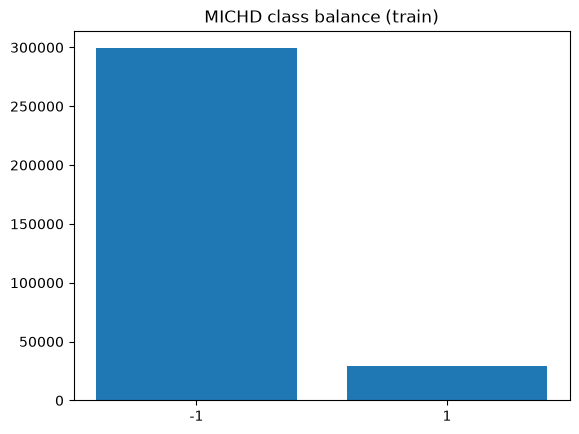

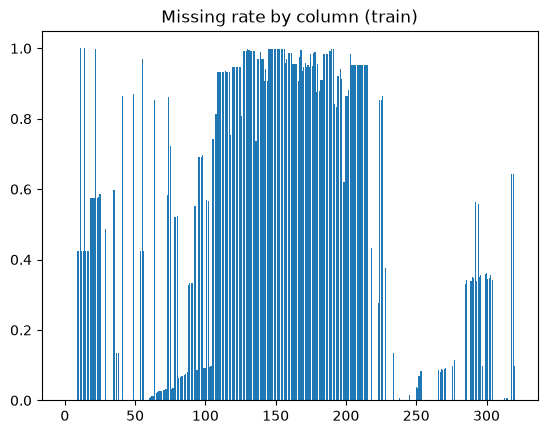

In [ ]:
n, d = x_train.shape
miss = eda.missing_count(x_train)
rates = eda.missing_rate(x_train)
drop = eda.constant_mask(x_train)
kinds = eda.classify_columns(x_train)

print(
    f"NaNs train: {miss.sum()}/{n * d} ({100 * miss.sum() / (n * d):.1f}%), "
    f"cols with NaN: {(miss > 0).sum()}/{d}"
)
miss_te = eda.missing_count(x_test)
n_te = x_test.shape[0]
print(
    f"NaNs test:  {miss_te.sum()}/{n_te * d} ({100 * miss_te.sum() / (n_te * d):.1f}%), "
    f"cols with NaN: {(miss_te > 0).sum()}/{d}"
)
print(f"constant cols: {int(drop.sum())}/{d}, indices: {np.flatnonzero(drop)}")
print("kinds:", {k: int(v.sum()) for k, v in kinds.items()})
print("cols with >50% missing:", int((rates > 0.5).sum()))

eda.plot_class_balance(y_train, title="MICHD class balance (train)")
eda.plot_missing_rates(rates, title="Missing rate by column (train)")


About 44.8% of train and test entries are NaN, with a similar column footprint (239 vs 232 columns touched). There is no obvious train vs test missingness shift. Six columns are constant (`[9, 11, 12, 18, 19, 22]`). Most features are ordinal (221), with 80 continuous and 14 binary. 147 columns exceed 50% missing and dominate the sparse bar chart.


## 1b. Missing rate threshold

**Choice:** `rate_miss = 0.5`. If more than half the values are missing, median impute invents most of the column and adds little reliable signal.

We do not drop rows: every test id needs a prediction, and a train only row filter would shift the distribution.

The next cell inspects a few high missing columns; the cell after that shows how many features we keep as the threshold moves.


cols with >50% missing: 147 e.g. [11 14 18 19 20 21 22 23 24 25 35 41 49 55 64]


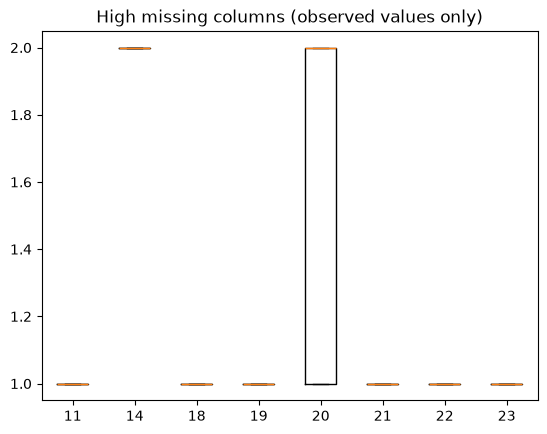

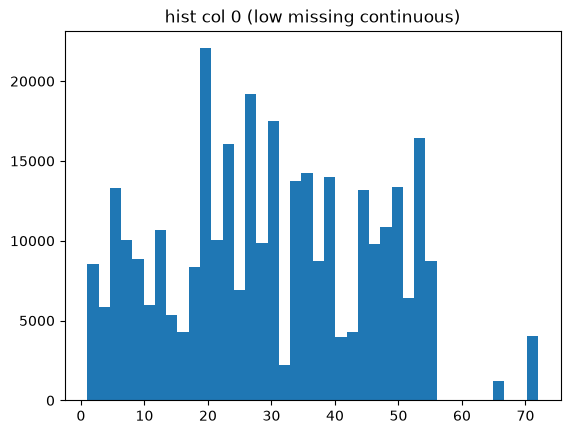

In [ ]:
import matplotlib.pyplot as plt

rate_miss = 0.5
hi_miss = np.flatnonzero(rates > rate_miss)
print(f"cols with >{rate_miss*100:g}% missing: {hi_miss.size} e.g. {hi_miss[:15]}")

eda.plot_feature_boxplots(
    x_train, hi_miss[:8], title="High missing columns (observed values only)"
)

cand = np.flatnonzero(kinds["continuous"] & (rates < 0.3) & (~drop))
col = int(cand[0])
plt.figure()
plt.hist(x_train[:, col][np.isfinite(x_train[:, col])], bins=40)
plt.title(f"hist col {col} (low missing continuous)")
plt.show()


The high missing boxplots still show some structure on the observed slice, but those columns are mostly empty, so median impute would invent most values. The low missing continuous histogram is the kind of feature the baseline should keep.


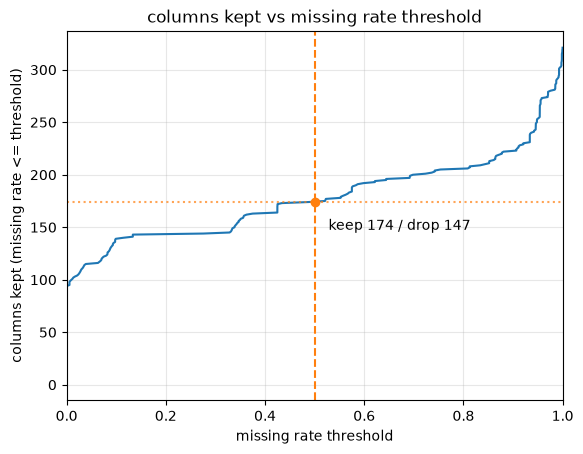

at rate_miss=0.5: 174 kept, 147 dropped


In [ ]:
n_keep = int((rates <= rate_miss).sum())
n_drop = int((rates > rate_miss).sum())
sorted_rates = np.sort(rates)

fig, ax = plt.subplots()
ax.plot(sorted_rates, np.arange(1, len(sorted_rates) + 1))
ax.axvline(rate_miss, color="C1", linestyle="--")
ax.axhline(n_keep, color="C1", linestyle=":", alpha=0.7)
ax.scatter([rate_miss], [n_keep], color="C1", zorder=3)
ax.annotate(
    f"keep {n_keep} / drop {n_drop}",
    xy=(rate_miss, n_keep),
    xytext=(10, -20),
    textcoords="offset points",
)
ax.set_xlabel("missing rate threshold")
ax.set_ylabel("columns kept (missing rate <= threshold)")
ax.set_title("columns kept vs missing rate threshold")
ax.set_xlim(0, 1)
ax.grid(True, alpha=0.3)
plt.show()
print(f"at rate_miss={rate_miss}: {n_keep} kept, {n_drop} dropped")


With `rate_miss = 0.5` the curve keeps 174 columns and drops 147. Adding the six constants (four of which already sit above 50% missing) removes 149 columns in total and leaves 172 features for the model. We keep all rows so every test id can be scored.


## 1c. Relation to the MICHD label

Two checks that matter for medical data:

1. **Missingness by class.** Scatter missing rate in class `-1` vs class `1`. Points on `y = x` mean missingness is shared. Points far off the diagonal mean missingness itself may be informative (not a bug: consider a missing indicator later).
2. **Standardized mean gap.** For low missing continuous or ordinal columns, `(mean_1 - mean_-1) / std` ranks which features separate the classes on a comparable scale.


cols with |missing gap| > 5%: 87/321, max gap=0.37
top |standardized mean gap|:
  col  26  +0.861
  col 248  +0.791
  col 246  +0.772
  col  58  +0.730
  col 249  +0.729
drop plan: 149 cols (6 constant, 147 high missing, overlap 4); keep 172


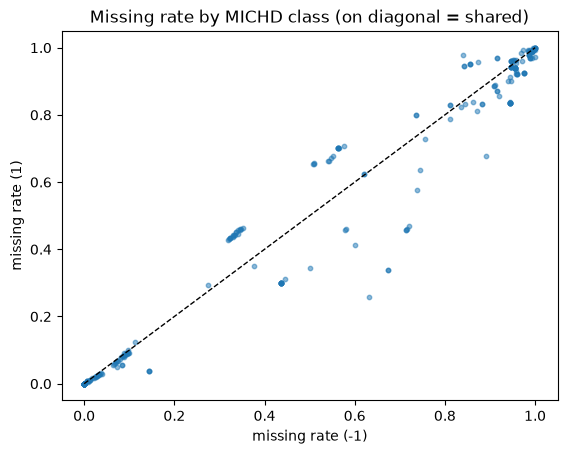

In [ ]:
rates_by_y = eda.missing_rate_by_class(x_train, y_train)
r_neg, r_pos = rates_by_y[-1], rates_by_y[1]
eda.plot_missing_rate_by_class(
    r_neg, r_pos, title="Missing rate by MICHD class (on diagonal = shared)"
)
miss_gap = np.abs(r_pos - r_neg)
print(
    f"cols with |missing gap| > 5%: {(miss_gap > 0.05).sum()}/{len(miss_gap)}, "
    f"max gap={miss_gap.max():.2f}"
)

cols, gaps = eda.mean_diff_by_class(
    x_train, y_train, col_mask=kinds["continuous"] | kinds["ordinal"]
)
top = np.argsort(np.abs(gaps))[::-1][:5]
print("top |standardized mean gap|:")
for j, g in zip(cols[top], gaps[top]):
    print(f"  col {int(j):3d}  {g:+.3f}")

const = eda.constant_mask(x_train)
hi = rates > rate_miss
print(
    f"drop plan: {(const | hi).sum()} cols "
    f"({const.sum()} constant, {hi.sum()} high missing, "
    f"overlap {(const & hi).sum()}); keep {(~(const | hi)).sum()}"
)


Missing rates mostly follow the diagonal: 87 columns differ by more than 5% across classes, with a max gap of 0.37, but the bulk of NaNs is shared. Median impute is therefore a fair baseline; the off diagonal columns are candidates for a missing indicator later, not blockers.

The strongest standardized mean gaps on low missing columns are `26, 248, 246, 58, 249` (up to about 0.86 std). They survive the 0.5 missing cut. Drop plan for the report: 149 columns out (6 constant, 147 high missing, overlap 4), 172 kept.


## 2. Preprocessing (fit stats without leakage)

1. Map labels to `{0, 1}` for logistic regression helpers.
2. Stratified 80/20 split (same positive rate in fit and val).
3. On the **fit** rows only: drop constants and columns with missing rate `> 0.5`, median impute, standardize.
4. Apply that frozen state to val and test (never refit on them).
5. Add a bias column of ones for the linear model.


In [ ]:
y01 = (y_train == 1).astype(float)
rng = np.random.default_rng(42)
val_frac = 0.2
max_missing_rate = 0.5

fit_idx, val_idx = prep.stratified_split(y01, val_frac, rng)
state = prep.fit_preprocessor(
    x_train[fit_idx], eps=1e-12, max_missing_rate=max_missing_rate
)
x_fit_clean = prep.transform(x_train[fit_idx], state)
x_val_clean = prep.transform(x_train[val_idx], state)
x_test_clean = prep.transform(x_test, state)

tx_fit = np.c_[np.ones(len(x_fit_clean)), x_fit_clean]
tx_val = np.c_[np.ones(len(x_val_clean)), x_val_clean]
tx_test = np.c_[np.ones(len(x_test_clean)), x_test_clean]

print("dropped cols:", int(state["drop"].sum()))
print("shapes fit/val/test:", tx_fit.shape, tx_val.shape, tx_test.shape)
print("fit/val size:", len(fit_idx), len(val_idx))
print("positive rate fit/val:", y01[fit_idx].mean(), y01[val_idx].mean())


dropped cols: 120
shapes fit/val/test: (262508, 202) (65627, 202) (109379, 202)
fit/val size: 262508 65627
positive rate fit/val: 0.08830207079403295 0.08830207079403295


After the fit only transform we have shapes `(262508, 173)`, `(65627, 173)`, `(109379, 173)`: 172 features plus a bias column. Fit and val both keep a positive rate of 0.0883, so stratification worked. Medians and scales were fit on the fit fold only.


## 3. Validation baseline

Train logistic regression on the fit fold. Predictions use score threshold 0 and labels `{-1, +1}`.

**Metrics:** F1 is the score used to choose a model and a cut. Accuracy, TNR, and TPR are reported beside it. Also compare predicted vs true positive rate on val.


In [ ]:
max_iters, gamma = 20, 0.05
w, loss = logistic_regression(
    y01[fit_idx], tx_fit, np.zeros(tx_fit.shape[1]), max_iters, gamma
)

scores = tx_val @ w
pred = np.where(scores >= 0, 1, -1)
truth = np.where(y01[val_idx] == 1, 1, -1)
accuracy = float(np.mean(pred == truth))
tnr = float(np.mean(pred[truth == -1] == -1))
tpr = float(np.mean(pred[truth == 1] == 1))
tp = float(np.sum((pred == 1) & (truth == 1)))
fp = float(np.sum((pred == 1) & (truth == -1)))
fn = float(np.sum((pred == -1) & (truth == 1)))
precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = 0.0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)
pred_pos_rate = float(np.mean(pred == 1))

print(f"max_iters={max_iters}, gamma={gamma}")
print(f"validation loss: {loss:.4f}")
print(f"f1: {f1:.4f}")
print(f"accuracy: {accuracy:.4f}")
print(f"TNR={tnr:.4f}, TPR={tpr:.4f}")
print(f"pred positive rate: {pred_pos_rate:.4f} (true {y01[val_idx].mean():.4f})")


Current iteration=0, loss=0.6931471805599453
max_iters=20, gamma=0.05
validation loss: 0.5391
accuracy: 0.8542
balanced accuracy: 0.7031 (TNR=0.8866, TPR=0.5196)
pred positive rate: 0.1493 (true 0.0883)


With `max_iters=20` and `gamma=0.05`, validation loss is about 0.54. The score cut is 0, so about 15% of rows are predicted positive. That file scored 0.391 F1 and 0.858 accuracy on the public leaderboard. Later cuts chosen for balanced accuracy predicted about 32% positive and lowered both public scores. Compare later runs by validation F1, and keep accuracy beside it.


## 4. Final fit and submission

After choosing hyperparameters on validation, refit preprocessing and the model on **all** labelled rows, predict on test, and write `Id,Prediction` with values in `{-1, +1}`.


In [ ]:
out_path = "submission_logistic_baseline.csv"

state_full = prep.fit_preprocessor(
    x_train, eps=1e-12, max_missing_rate=max_missing_rate
)
x_train_clean = prep.transform(x_train, state_full)
x_test_clean = prep.transform(x_test, state_full)
tx_train = np.c_[np.ones(x_train_clean.shape[0]), x_train_clean]
tx_test = np.c_[np.ones(x_test_clean.shape[0]), x_test_clean]

w_final, final_loss = logistic_regression(
    y01, tx_train, np.zeros(tx_train.shape[1]), max_iters, gamma
)
y_pred = np.where(tx_test @ w_final >= 0, 1, -1)
create_csv_submission(ids_test, y_pred, out_path)

labels, counts = np.unique(y_pred, return_counts=True)
print(f"saved {out_path}, loss={final_loss:.4f}")
print("prediction counts:", dict(zip(labels.astype(int), counts.astype(int))))


Current iteration=0, loss=0.6931471805599453
saved submission_logistic_baseline.csv, loss=0.5391
prediction counts: {np.int64(-1): np.int64(93053), np.int64(1): np.int64(16326)}


The file `submission_logistic_baseline.csv` has one `{-1,+1}` prediction per test id. On a previous full refit the model predicted roughly 93k negatives and 16k positives (about 14.6% positive), a bit above the 8.8% train rate. That is acceptable for a first baseline; threshold or regularization can adjust it in later experiments.


## 5. Submissions for every model

Six models are available in `implementations.py`: least squares, ridge regression, gradient descent, stochastic gradient descent, logistic regression, and regularized logistic regression. The run fits the names in `config/train.json`. That file also holds the class weight, the validation fraction, the penalty and step-size grids, and the early-stopping caps. `config/features.json` holds the imputation, the BMI cap, the missing-indicator floor, and the missing-rate cutoff.

Missing entries are filled with the column mode, but only after the BRFSS 2015 codebook recode in `src/codebook_features.py`. Do-not-know and refused codes are set to missing first. On a yes or no item those codes are 7 and 9. On the day counts, 77 and 99 are missing and 88 means zero days. The choices and the reason for every column are in `feature_choices.md`. Survey fields such as `IYEAR`, `FMONTH`, and `WEIGHT2` are removed there, before any column score. Sparse health items stay. A blank is not a measured zero. The mode, the drop mask, and the standardization are fit on the training rows only and frozen for test. Constant columns are dropped. Columns are not dropped for being mostly empty: `max_missing_rate` in `config/features.json` is 1, so a high missing rate is kept. Mode had the best validation F1 in the three way fill comparison (0.418, against 0.417 for the median and 0.416 for the mean), so the imputation is fixed and is no longer part of the search.

After that cleaning, `leave_one_column_relation` still scores every remaining column. The score is a report, not a gate. `column_significance.csv` lists the columns strongest first, and the model keeps all of them. A column the codebook dropped cannot come back, because it is no longer in the matrix. Before the mode fill, a missing indicator is added for every recoded column whose training missing rate is at least `missing_flag_min_rate`, and always for income, high cholesterol, fruit, vegetables, seat belt, strength training, and the HIV test. `_BMI5` is capped at the value in `config/features.json` before its square. The nonlinear terms, used by every model including logistic regression, are the square of `_AGE80`, the square of capped `_BMI5`, and the products of age with sex, smoking, diagnosed diabetes, general health, and high cholesterol, plus BMI with smoking. The logistic sigmoid bends the score. It does not create those products, so logistic regression is fit on the same expanded matrix as the linear models. Pairwise products of the strongest 20 columns are not built.

Linear models train on labels `{-1, +1}`. Logistic models train on `{0, 1}`. Each training row is weighted by `positive_class_weights`. The total weight of target 1, relative to the negative class, is `positive_class_cost` in `config/train.json`. It is 2. The cutoff is chosen for class 1. A stratified 80/20 split is the validation fold. The grid searches the ridge penalty, the logistic penalty, the step size, and, through early stopping, the number of steps. For every setting, the decision threshold is the cut with the best validation F1. F1 is the class-1 score: it uses precision and recall of target 1, and it ignores how easy it is to recognize the majority class. If two cuts tie on F1, the higher accuracy wins. The winning penalty, step size, and stopped step count are refit on all labelled rows. Predictions go to `submissions/<model>_mode_expanded.csv`.

Training uses NumPy on the CPU. These functions are the course implementations, and NumPy does not run them on the Apple GPU. The project also disallows PyTorch, which is what would be needed to reach Metal. The feature matrices have a few hundred columns, so the heavy step is a small matrix product and a GPU would not remove much time.

Gradient and logistic fits try the same step sizes as before, and they may run much longer: 2000 steps for gradient descent, 200000 for stochastic gradient descent, and 500 for logistic regression. Every few steps the fit checks validation AUC. After 5 checks with no gain of 0.0001 it stops and keeps the best weights. The full refit then uses that same step count. Set `USE_GPU=1` only on a machine with CuPy and CUDA. Full batch steps can use the GPU. Stochastic gradient descent stays on the CPU. The same run is `python train_early_stop.py` from the project root. Compare train loss with validation loss in the printout. A large gap means the fit is memorizing the training fold. The codebook matrix is much smaller than the old pairwise expansion, so the closed form losses should stay close. Earlier unweighted linear models sat near validation F1 0.42, recall about 0.55, and precision about 0.33, with accuracy about 0.86. Accuracy near 0.86 is still expected, because the majority class is already about 91 percent and the cutoff is chosen for F1.

In [ ]:
import contextlib
import io
import os

import src.codebook_features as codebook
import src.early_stopping as early
import src.train_config as train_config

np.seterr(divide="ignore", over="ignore", invalid="ignore")

FEATURES, TRAIN = train_config.load()
MAX_MISSING_RATE = float(FEATURES["max_missing_rate"])
MISSING_FLAG_MIN_RATE = float(FEATURES["missing_flag_min_rate"])
EPS = float(FEATURES["eps"])
IMPUTE = FEATURES["impute"]
codebook.BMI_CAP = float(FEATURES["bmi_cap"])
if os.environ.get("USE_GPU", "") == "1":
    USE_GPU = True
elif os.environ.get("USE_GPU", "") == "0":
    USE_GPU = False
else:
    USE_GPU = bool(TRAIN["use_gpu"])
GRIDS = TRAIN["grids"]
STOP = TRAIN["early_stopping"]
SUBMISSION_DIR = TRAIN["submission_dir"]
MODELS = tuple(TRAIN["models"])
POSITIVE_CLASS_COST = float(TRAIN["positive_class_cost"])


def add_bias(x):
    return np.c_[np.ones(x.shape[0]), x]


def classification_scores(scores, y_pm1, threshold):
    """Accuracy, F1, F2, TPR, and TNR for labels in {-1, +1}.

    F2 weighs recall twice as much as precision.
    """
    pred = np.where(scores >= threshold, 1, -1)
    positive = y_pm1 == 1
    negative = ~positive
    tp = float(np.sum((pred == 1) & positive))
    fp = float(np.sum((pred == 1) & negative))
    fn = float(np.sum((pred == -1) & positive))
    tpr = tp / float(positive.sum())
    tnr = float(np.mean(pred[negative] == -1))
    accuracy = float(np.mean(pred == y_pm1))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 0.0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)
    if precision + recall == 0:
        f2 = 0.0
    else:
        f2 = 5 * precision * recall / (4 * precision + recall)
    return {
        "accuracy": accuracy,
        "f1": f1,
        "f2": f2,
        "precision": precision,
        "recall": recall,
        "tpr": tpr,
        "tnr": tnr,
    }


def choose_threshold(scores, y_pm1):
    """Cut on the linear score that maximizes validation F1.

    F1 is the class-1 score. An equal F1 keeps the cut with higher accuracy.
    The score 0 is always a candidate. Class weight stays at 2.
    """
    grid = np.linspace(0.0, 1.0, 201)
    candidates = np.concatenate([np.quantile(scores, grid), np.array([0.0])])
    best_threshold, best_f1, best_accuracy = 0.0, -1.0, -1.0
    for threshold in np.unique(candidates):
        metrics = classification_scores(scores, y_pm1, float(threshold))
        better_f1 = metrics["f1"] > best_f1
        tied_f1 = metrics["f1"] == best_f1 and metrics["accuracy"] > best_accuracy
        if better_f1 or tied_f1:
            best_f1 = metrics["f1"]
            best_accuracy = metrics["accuracy"]
            best_threshold = float(threshold)
    return best_threshold, best_f1


def model_loss(kind, y_pm1, y01, tx, w):
    if kind in ("logistic", "reg_logistic"):
        return float(calculate_loss(y01, tx, w))
    return float(compute_loss(y_pm1, tx, w))


def parameter_grid(kind):
    """Hyperparameter combinations searched on the validation fold."""
    if kind == "least_squares":
        return ({"lambda": 0.0, "gamma": 0.0, "max_iters": 0},)
    if kind == "ridge":
        return tuple(
            {"lambda": lam, "gamma": 0.0, "max_iters": 0}
            for lam in GRIDS["ridge_lambda"]
        )
    if kind == "gd":
        return tuple(
            {
                "lambda": 0.0,
                "gamma": gamma,
                "max_iters": STOP["max_iters"]["gd"],
            }
            for gamma in GRIDS["gd_gamma"]
        )
    if kind == "sgd":
        return tuple(
            {
                "lambda": 0.0,
                "gamma": gamma,
                "max_iters": STOP["max_iters"]["sgd"],
            }
            for gamma in GRIDS["sgd_gamma"]
        )
    if kind == "logistic":
        return tuple(
            {
                "lambda": 0.0,
                "gamma": gamma,
                "max_iters": STOP["max_iters"]["logistic"],
            }
            for gamma in GRIDS["logistic_gamma"]
        )
    if kind == "reg_logistic":
        return tuple(
            {
                "lambda": lam,
                "gamma": gamma,
                "max_iters": STOP["max_iters"]["reg_logistic"],
            }
            for lam in GRIDS["reg_logistic_lambda"]
            for gamma in GRIDS["logistic_gamma"]
        )
    raise ValueError("unknown model: " + kind)


def train_quiet(
    kind, y_pm1, y01, tx, lambda_, gamma, max_iters, tx_val=None, y_val=None,
):
    """Fit one model. Iterative models stop when validation AUC stalls."""
    sample_weights = weights.positive_class_weights(y_pm1, POSITIVE_CLASS_COST)
    if kind in early.ITERATIVE:
        if kind == "sgd":
            np.random.seed(int(TRAIN["seed"]))
        return early.fit_iterative(
            kind,
            y_pm1,
            y01,
            tx,
            sample_weights,
            lambda_,
            gamma,
            max_iters,
            tx_val,
            y_val,
            patience=int(STOP["patience"]),
            eval_every=int(STOP["eval_every"][kind]),
            use_gpu=USE_GPU,
            min_auc_gain=float(STOP["min_auc_gain"]),
        )
    w, loss = weights.fit_positive_class_weights(
        kind,
        y_pm1,
        y01,
        tx,
        sample_weights,
        lambda_,
        gamma,
        max_iters,
    )
    return w, loss, 0


def finite_fit(w, loss):
    return bool(np.isfinite(loss)) and bool(np.isfinite(w).all())


def select_params(kind, y_fit, y01_fit, tx_fit, y_val, tx_val):
    """Pick the grid point with the best validation F1.

    The penalty, step size, and early-stopped step count are the training
    parameters. The F1 cutoff is chosen after the fit, on the same scores.
    """
    best = None
    n_skipped = 0
    for params in parameter_grid(kind):
        w, loss, stopped = train_quiet(
            kind,
            y_fit,
            y01_fit,
            tx_fit,
            params["lambda"],
            params["gamma"],
            params["max_iters"],
            tx_val,
            y_val,
        )
        if not finite_fit(w, loss):
            n_skipped += 1
            continue
        scores = tx_val @ w
        threshold, f1 = choose_threshold(scores, y_val)
        metrics = classification_scores(scores, y_val, threshold)
        better = best is None or f1 > best["f1"]
        tied = (
            best is not None
            and f1 == best["f1"]
            and metrics["accuracy"] > best["accuracy"]
        )
        if better or tied:
            best = {
                "lambda": params["lambda"],
                "gamma": params["gamma"],
                "max_iters": stopped,
                "threshold": threshold,
                "f1": f1,
                "accuracy": metrics["accuracy"],
                "w": w,
            }
    if best is None:
        raise RuntimeError("every setting diverged for " + kind)
    best["n_tried"] = len(parameter_grid(kind))
    best["n_skipped"] = n_skipped
    return best


def restore_required(cleaned, names):
    """Put back a required column the group drop removed, as zeros.

    A sex split makes SEX constant, so the preprocessor drops it. The age
    product with sex is then zero, which is already implied by a separate
    model for that sex.
    """
    required = (
        "_AGE80", "_BMI5", "SEX", "_SMOKER3", "diab_yes", "GENHLTH", "_RFCHOL",
    )
    missing = [name for name in required if name not in names]
    if not missing:
        return cleaned, list(names)
    zeros = np.zeros((cleaned.shape[0], len(missing)))
    return np.column_stack([cleaned, zeros]), list(names) + missing


def split_groups(split_name):
    """Boolean train and test masks for each piece of one split."""
    sex_train = x_train_cb[:, cb_names.index("SEX")]
    sex_test = x_test_cb[:, cb_names.index("SEX")]
    if split_name == "sex":
        groups = (
            ("male", sex_train == 1, sex_test == 1),
            ("female", sex_train == 0, sex_test == 0),
        )
    elif split_name == "age65":
        cutoff = float(TRAIN.get("age_cutoff", 65))
        age_train = x_train_cb[:, cb_names.index("_AGE80")]
        age_test = x_test_cb[:, cb_names.index("_AGE80")]
        groups = (
            (
                "under_65",
                np.isfinite(age_train) & (age_train < cutoff),
                np.isfinite(age_test) & (age_test < cutoff),
            ),
            (
                "age_65_plus",
                (~np.isfinite(age_train)) | (age_train >= cutoff),
                (~np.isfinite(age_test)) | (age_test >= cutoff),
            ),
        )
    else:
        raise ValueError("unknown split: " + split_name)
    train_cover = np.zeros(x_train_cb.shape[0], dtype=bool)
    test_cover = np.zeros(x_test_cb.shape[0], dtype=bool)
    for _label, train_mask, test_mask in groups:
        train_cover |= train_mask
        test_cover |= test_mask
    if not train_cover.all() or not test_cover.all():
        raise RuntimeError(split_name + " left some rows in no group")
    return groups


def fit_split_logistic(split_name):
    """One logistic model per group, each with its own validation F1 cutoff."""
    kind = "logistic"
    val_pred = np.zeros(y_pm1.shape[0])
    test_pred = np.zeros(x_test_cb.shape[0], dtype=int)
    for label, train_mask, test_mask in split_groups(split_name):
        train_rows = np.flatnonzero(train_mask)
        test_rows = np.flatnonzero(test_mask)
        group_fit = np.intersect1d(fit_idx, train_rows)
        group_val = np.intersect1d(val_idx, train_rows)
        if not np.any(y_pm1[group_fit] == 1) or not np.any(y_pm1[group_val] == 1):
            raise RuntimeError(label + " is missing target 1 in fit or validation")
        # Drop mask from the whole group, so the fit fold and the refit keep
        # the same columns. Fill and scale for the search use the fit rows only.
        state_columns = prep.fit_preprocessor(
            x_train_cb[train_rows], EPS, MAX_MISSING_RATE, IMPUTE
        )
        drop = state_columns["drop"]
        raw_names, _source = codebook.columns_after_drop(cb_names, cb_source, drop)
        kept_fit = x_train_cb[group_fit][:, ~drop]
        fill = prep.column_fill(kept_fit, IMPUTE)
        means, scales = prep.standardization_stats(
            prep.impute_values(kept_fit, fill), EPS
        )
        state_group = {
            "drop": drop,
            "impute": IMPUTE,
            "fill": fill,
            "medians": fill,
            "means": means,
            "scales": scales,
        }
        x_group_fit, group_names = restore_required(
            prep.transform(x_train_cb[group_fit], state_group), raw_names
        )
        x_group_val, _names_val = restore_required(
            prep.transform(x_train_cb[group_val], state_group), raw_names
        )
        clinical = features.fit_clinical_terms(x_group_fit, group_names, EPS)
        tx_group_fit = add_bias(features.transform_clinical_terms(x_group_fit, clinical))
        tx_group_val = add_bias(features.transform_clinical_terms(x_group_val, clinical))
        chosen = select_params(
            kind,
            y_pm1[group_fit],
            y01[group_fit],
            tx_group_fit,
            y_pm1[group_val],
            tx_group_val,
        )
        threshold = chosen["threshold"]
        group_val_pred = np.where(tx_group_val @ chosen["w"] >= threshold, 1, -1)
        val_pred[group_val] = group_val_pred
        group_metrics = classification_scores(
            group_val_pred.astype(float), y_pm1[group_val], 0.0
        )
        state_all = prep.fit_preprocessor(
            x_train_cb[train_rows], EPS, MAX_MISSING_RATE, IMPUTE
        )
        raw_all, _source_all = codebook.columns_after_drop(
            cb_names, cb_source, state_all["drop"]
        )
        if raw_all != raw_names:
            raise RuntimeError(label + " kept different columns on the full group")
        x_group_all, all_names = restore_required(
            prep.transform(x_train_cb[train_rows], state_all), raw_all
        )
        x_group_test, _test_names = restore_required(
            prep.transform(x_test_cb[test_rows], state_all), raw_all
        )
        clinical_all = features.fit_clinical_terms(x_group_all, all_names, EPS)
        tx_group_all = add_bias(
            features.transform_clinical_terms(x_group_all, clinical_all)
        )
        tx_group_test = add_bias(
            features.transform_clinical_terms(x_group_test, clinical_all)
        )
        w_full, full_loss, _stopped = train_quiet(
            kind,
            y_pm1[train_rows],
            y01[train_rows],
            tx_group_all,
            chosen["lambda"],
            chosen["gamma"],
            chosen["max_iters"],
        )
        if not finite_fit(w_full, full_loss):
            raise RuntimeError("full refit diverged for " + label)
        test_pred[test_rows] = np.where(tx_group_test @ w_full >= threshold, 1, -1)
        print(
            f"{split_name:8} {label:12} n={train_rows.size} "
            f"gamma={chosen['gamma']:.4g} iters={chosen['max_iters']} "
            f"thr={threshold:.3f} "
            f"f1 {group_metrics['f1']:.3f} "
            f"rec {group_metrics['recall']:.3f} "
            f"prec {group_metrics['precision']:.3f} "
            f"acc {group_metrics['accuracy']:.3f}",
            flush=True,
        )
    if np.any(test_pred == 0):
        raise RuntimeError(split_name + " left a test row without a prediction")
    if np.any(val_pred[val_idx] == 0):
        raise RuntimeError(split_name + " left a validation row without a prediction")
    overall = classification_scores(val_pred[val_idx], y_pm1[val_idx], 0.0)
    path = os.path.join(SUBMISSION_DIR, f"logistic_{split_name}.csv")
    create_csv_submission(ids_test, test_pred, path)
    print(
        f"{split_name:8} {'overall':12} "
        f"f1 {overall['f1']:.3f} rec {overall['recall']:.3f} "
        f"prec {overall['precision']:.3f} acc {overall['accuracy']:.3f} "
        f"test_pos={float(np.mean(test_pred == 1)):.3f} {path}",
        flush=True,
    )
    return overall["f1"], path


os.makedirs(SUBMISSION_DIR, exist_ok=True)
rng = np.random.default_rng(int(TRAIN["seed"]))
y01 = (y_train == 1).astype(float)
y_pm1 = y_train.astype(float)
fit_idx, val_idx = prep.stratified_split(y01, float(TRAIN["val_fraction"]), rng)
sample_weights = weights.positive_class_weights(y_pm1, POSITIVE_CLASS_COST)
positive = y_pm1 == 1
weight_ratio = sample_weights[positive].sum() / sample_weights[~positive].sum()
print(
    f"models={','.join(MODELS)} "
    f"positive_class_weights cost={POSITIVE_CLASS_COST:g} "
    f"positive_over_negative={weight_ratio:.3f}"
)

base_train, base_names, _base_source = codebook.transform_codebook(
    x_train, flag_names=()
)
always_flags = [name for name, _flag in codebook.MISSING_FLAGS]
flag_names = codebook.choose_flag_names(
    base_train, base_names, MISSING_FLAG_MIN_RATE, always_flags
)
x_train_cb, cb_names, cb_source = codebook.transform_codebook(
    x_train, flag_names=flag_names
)
x_test_cb, cb_names_test, _cb_source_test = codebook.transform_codebook(
    x_test, flag_names=flag_names
)
if cb_names != cb_names_test:
    raise RuntimeError("train and test codebook columns differ")

state_fit = prep.fit_preprocessor(
    x_train_cb[fit_idx], EPS, MAX_MISSING_RATE, IMPUTE
)
x_fit = prep.transform(x_train_cb[fit_idx], state_fit)
x_val = prep.transform(x_train_cb[val_idx], state_fit)
names_fit, source_fit = codebook.columns_after_drop(
    cb_names, cb_source, state_fit["drop"]
)
marginal_gap = features.association_with_target(x_fit, y_pm1[fit_idx])
partial_r2, _delta_rss = column_significance.leave_one_column_relation(
    x_fit, y_pm1[fit_idx]
)
kept_mask = np.ones(len(names_fit), dtype=bool)
significance_path = "column_significance.csv"
column_significance.write_column_significance(
    significance_path,
    source_fit,
    marginal_gap,
    partial_r2,
    kept_mask,
    feature_names=names_fit,
)
print(f"wrote {significance_path}", flush=True)
map_fit = features.fit_clinical_terms(x_fit, names_fit, EPS)
tx_fit = add_bias(features.transform_clinical_terms(x_fit, map_fit))
tx_val = add_bias(features.transform_clinical_terms(x_val, map_fit))

state_full = prep.fit_preprocessor(x_train_cb, EPS, MAX_MISSING_RATE, IMPUTE)
x_all = prep.transform(x_train_cb, state_full)
x_test_std = prep.transform(x_test_cb, state_full)
names_full, _source_full = codebook.columns_after_drop(
    cb_names, cb_source, state_full["drop"]
)
if names_full != names_fit:
    raise RuntimeError("fit fold and full sample kept different codebook columns")
map_full = features.fit_clinical_terms(x_all, names_full, EPS)
tx_train = add_bias(features.transform_clinical_terms(x_all, map_full))
tx_test = add_bias(features.transform_clinical_terms(x_test_std, map_full))
score_order = np.argsort(-partial_r2, kind="mergesort")
print(
    f"{IMPUTE}: codebook {len(base_names)}, flags {len(flag_names)}, "
    f"cleaned {x_all.shape[1]}, "
    f"squares {map_fit['n_squares']}, products {map_fit['n_products']}, "
    f"design {tx_fit.shape[1] - 1}",
    flush=True,
)
print(
    "strongest codebook columns",
    [names_fit[int(index)] for index in score_order[:8]],
    "partial_r2",
    [float(f"{partial_r2[int(index)]:.4e}") for index in score_order[:8]],
    flush=True,
)

y_fit, y_val = y_pm1[fit_idx], y_pm1[val_idx]
y01_fit, y01_val = y01[fit_idx], y01[val_idx]

rows = []
pooled_models = MODELS if TRAIN.get("train_pooled", True) else ()
for kind in pooled_models:
    chosen = select_params(kind, y_fit, y01_fit, tx_fit, y_val, tx_val)
    w_fit = chosen["w"]
    threshold = chosen["threshold"]
    lam = chosen["lambda"]
    gamma = chosen["gamma"]
    max_iters = chosen["max_iters"]

    train_loss = model_loss(kind, y_fit, y01_fit, tx_fit, w_fit)
    val_loss = model_loss(kind, y_val, y01_val, tx_val, w_fit)
    train_metrics = classification_scores(tx_fit @ w_fit, y_fit, threshold)
    val_metrics = classification_scores(tx_val @ w_fit, y_val, threshold)

    w_full, full_loss, _stopped = train_quiet(
        kind, y_pm1, y01, tx_train, lam, gamma, max_iters
    )
    if not finite_fit(w_full, full_loss):
        raise RuntimeError("full refit diverged for " + kind)
    y_pred = np.where(tx_test @ w_full >= threshold, 1, -1)
    path = os.path.join(SUBMISSION_DIR, f"{kind}_mode_expanded.csv")
    create_csv_submission(ids_test, y_pred, path)
    pos_rate = float(np.mean(y_pred == 1))
    rows.append(
        {
            "model": kind,
            "impute": IMPUTE,
            "lambda": lam,
            "gamma": gamma,
            "max_iters": max_iters,
            "threshold": threshold,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_f1": train_metrics["f1"],
            "val_f1": val_metrics["f1"],
            "train_f2": train_metrics["f2"],
            "val_f2": val_metrics["f2"],
            "val_precision": val_metrics["precision"],
            "val_recall": val_metrics["recall"],
            "val_accuracy": val_metrics["accuracy"],
            "val_tpr": val_metrics["tpr"],
            "val_tnr": val_metrics["tnr"],
            "test_pos": pos_rate,
            "path": path,
            "n_tried": chosen["n_tried"],
            "n_skipped": chosen["n_skipped"],
        }
    )
    print(
        f"{kind:16} {IMPUTE:6} tried={chosen['n_tried']} "
        f"skipped={chosen['n_skipped']} lam={lam:.1e} "
        f"gamma={gamma:.4g} iters={max_iters} thr={threshold:.3f} "
        f"f1 {train_metrics['f1']:.3f}/{val_metrics['f1']:.3f} "
        f"rec {val_metrics['recall']:.3f} prec {val_metrics['precision']:.3f} "
        f"acc {val_metrics['accuracy']:.3f} "
        f"loss {train_loss:.4f}/{val_loss:.4f} "
        f"tpr={val_metrics['tpr']:.3f} tnr={val_metrics['tnr']:.3f} "
        f"test_pos={pos_rate:.3f}",
        flush=True,
    )

print(f"wrote {len(rows)} submission files in {SUBMISSION_DIR}/")
split_scores = []
for split_name in TRAIN.get("group_splits", []):
    split_f1, split_path = fit_split_logistic(split_name)
    split_scores.append((split_f1, split_name, split_path))
if split_scores:
    best_f1, best_name, best_path = max(split_scores)
    print(
        f"best group split {best_name} validation F1 {best_f1:.3f} {best_path}"
    )
print(
    "Class weight is positive_class_cost in config/train.json. "
    "The cutoff maximizes validation F1, the class-1 score. "
    "A group split fits logistic regression separately in each group."
)
